# Previsão de churn · Loja Horizonte

Quais clientes vão parar de comprar? Um modelo de **regressão logística** treinado com 1.600 clientes e testado com outros 400 que ele nunca viu.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, precision_score, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score

df = pd.read_csv('dados/churn_clientes.csv')
df.head()

,cliente,meses_cliente,gasto_mensal,reclamacoes_abertas,dias_ultima_compra,usa_app,churn
0,1,42,61,0,30,1,0
1,2,40,290,0,15,0,0
2,3,47,236,1,31,1,0
3,4,34,166,2,80,1,0
4,5,24,260,0,39,0,0


## 1. Conhecendo a base

In [2]:
print(df.shape)
print(f"Taxa de churn: {df['churn'].mean():.1%}")
df.describe().round(1)

(2000, 7)
Taxa de churn: 32.5%


,cliente,meses_cliente,gasto_mensal,reclamacoes_abertas,dias_ultima_compra,usa_app,churn
count,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0
mean,1000.5,30.2,237.4,0.9,43.9,0.5,0.3
std,577.5,17.1,210.6,1.2,40.4,0.5,0.5
min,1.0,1.0,20.0,0.0,0.0,0.0,0.0
25%,500.8,15.0,81.0,0.0,13.0,0.0,0.0
50%,1000.5,30.0,172.5,0.0,32.0,0.0,0.0
75%,1500.2,45.0,319.0,1.0,61.2,1.0,1.0
max,2000.0,60.0,1000.0,5.0,180.0,1.0,1.0


In [3]:
df.groupby('churn').mean(numeric_only=True).drop(columns='cliente').round(1)

,meses_cliente,gasto_mensal,reclamacoes_abertas,dias_ultima_compra,usa_app
churn,,,,,
0,33.5,259.7,0.6,39.1,0.5
1,23.4,190.9,1.5,53.8,0.4


Quem sai tem, em média, menos tempo de casa, mais reclamações abertas, mais dias sem comprar e usa menos o aplicativo.

## 2. Treino e teste

In [4]:
FEATURES = ['meses_cliente', 'gasto_mensal', 'reclamacoes_abertas', 'dias_ultima_compra', 'usa_app']
X, y = df[FEATURES], df['churn']
# os 1.600 primeiros para treino e os 400 últimos para teste (mesma divisão da demo do portfólio)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=400, shuffle=False)

modelo = make_pipeline(StandardScaler(), LogisticRegression())
modelo.fit(X_tr, y_tr)
print(f'Treino: {len(X_tr)} clientes | Teste: {len(X_te)} clientes')

Treino: 1600 clientes | Teste: 400 clientes


## 3. Avaliação no teste

Acurácia : 79.5%
Precisão : 69.1%  (dos que o modelo marcou como risco, quantos saíram)
Recall   : 55.1%  (dos que saíram, quantos o modelo pegou)
AUC      : 0.840


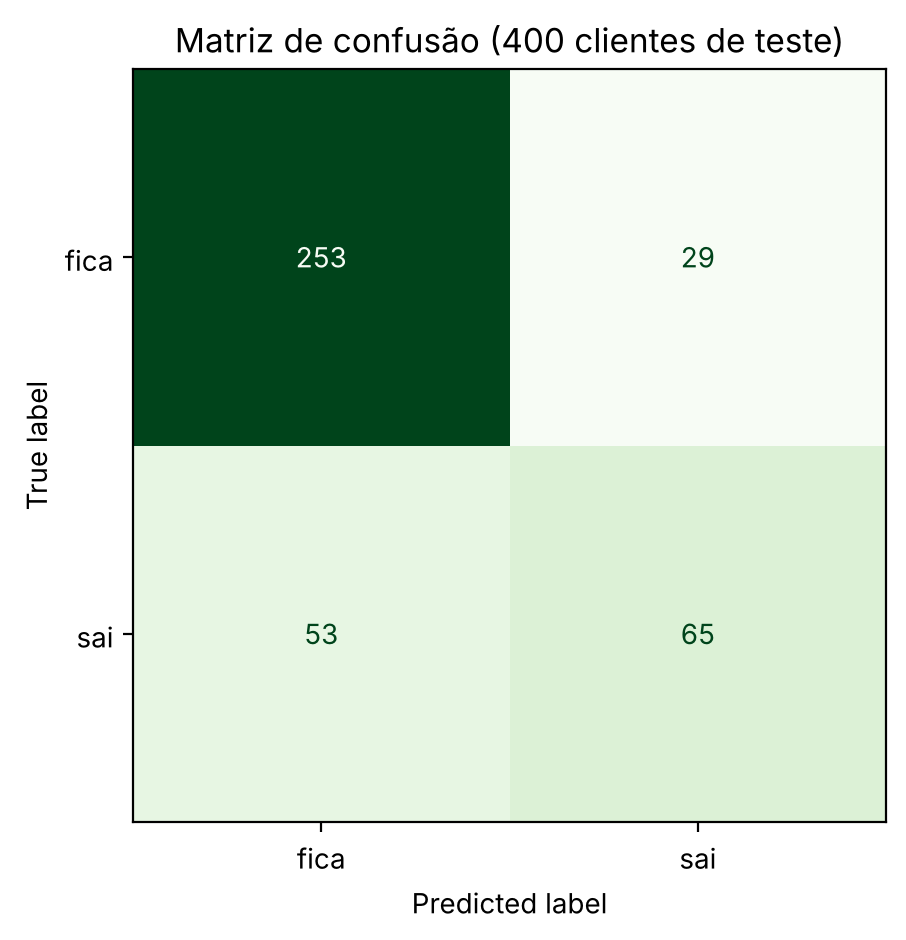

In [5]:
pred = modelo.predict(X_te)
prob = modelo.predict_proba(X_te)[:, 1]
print(f'Acurácia : {accuracy_score(y_te, pred):.1%}')
print(f'Precisão : {precision_score(y_te, pred):.1%}  (dos que o modelo marcou como risco, quantos saíram)')
print(f'Recall   : {recall_score(y_te, pred):.1%}  (dos que saíram, quantos o modelo pegou)')
print(f'AUC      : {roc_auc_score(y_te, prob):.3f}')
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=['fica', 'sai']).plot(cmap='Greens', colorbar=False)
plt.title('Matriz de confusão (400 clientes de teste)'); plt.tight_layout(); plt.savefig('graficos/matriz_confusao.png', dpi=120); plt.show()

O recall mostra quantos clientes que saíram o modelo pegou. Para retenção, deixar alguém escapar custa mais que um alarme falso. Por isso testo um limite de decisão menor que 50%.

In [6]:
for limite in [0.5, 0.4, 0.3]:
    p = (prob >= limite).astype(int)
    print(f'limite {limite:.0%}: acurácia {accuracy_score(y_te, p):.1%} | recall {recall_score(y_te, p):.1%} | precisão {precision_score(y_te, p):.1%}')

limite 50%: acurácia 79.5% | recall 55.1% | precisão 69.1%
limite 40%: acurácia 78.2% | recall 68.6% | precisão 61.8%
limite 30%: acurácia 71.5% | recall 79.7% | precisão 51.1%


## 4. O que mais pesa no churn

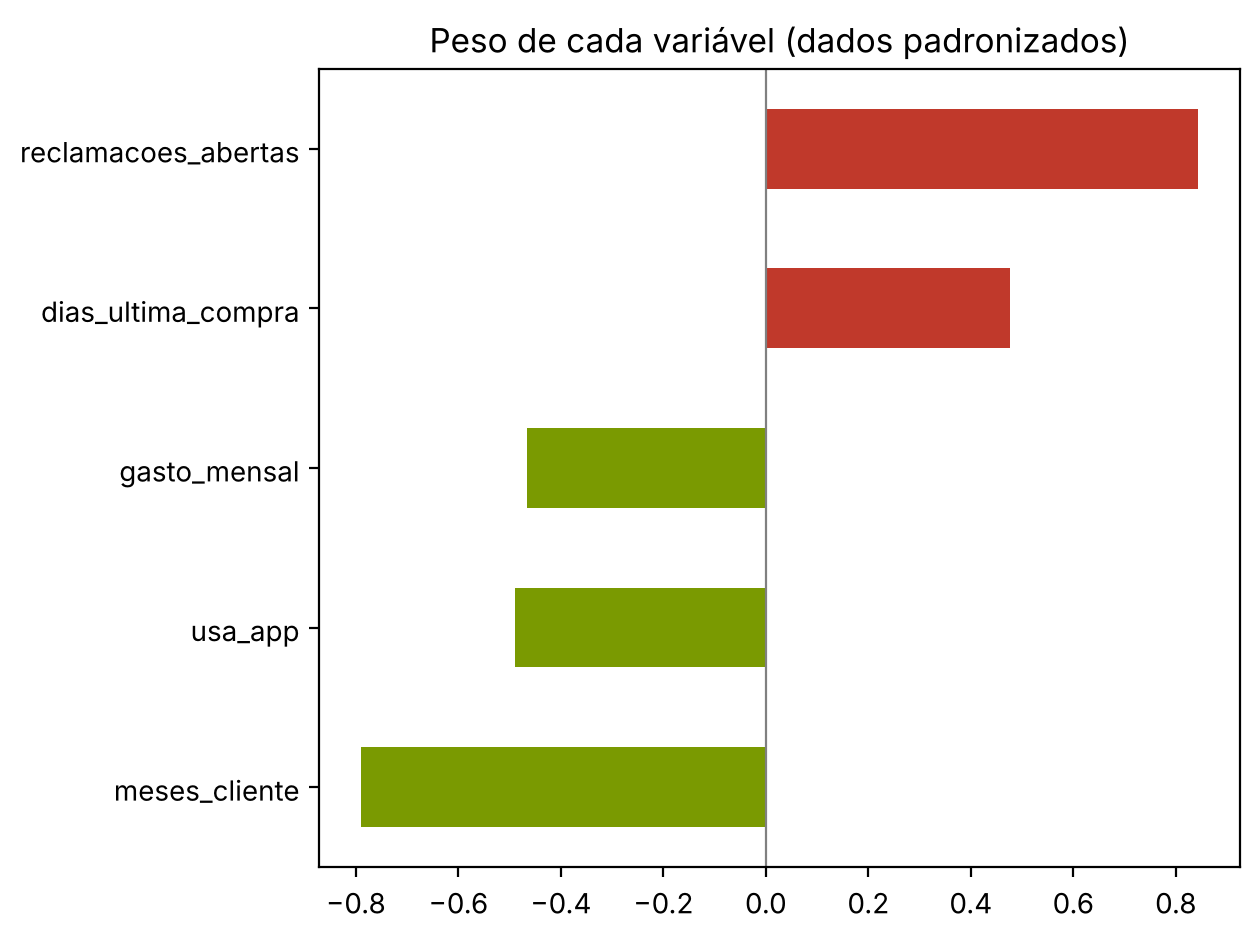

meses_cliente         -0.79
usa_app               -0.49
gasto_mensal          -0.47
dias_ultima_compra     0.48
reclamacoes_abertas    0.84
dtype: float64

In [7]:
coef = pd.Series(modelo[-1].coef_[0], index=FEATURES).sort_values()
ax = coef.plot(kind='barh', color=['#7a9a01' if v < 0 else '#c0392b' for v in coef], title='Peso de cada variável (dados padronizados)')
ax.axvline(0, color='grey', lw=.8); plt.tight_layout(); plt.savefig('graficos/pesos.png', dpi=120); plt.show()
coef.round(2)

Vermelho aumenta a chance de sair, verde diminui. **Reclamações abertas** e **dias sem comprar** empurram para o churn. **Tempo de casa**, **gasto mensal** e **uso do app** seguram o cliente.

## 5. Usando o modelo

In [8]:
clientes_novos = pd.DataFrame([
    {'meses_cliente': 36, 'gasto_mensal': 450, 'reclamacoes_abertas': 0, 'dias_ultima_compra': 10,  'usa_app': 1},
    {'meses_cliente': 4,  'gasto_mensal': 120, 'reclamacoes_abertas': 3, 'dias_ultima_compra': 90,  'usa_app': 0},
], index=['cliente fiel', 'cliente em risco'])
clientes_novos['prob_churn_%'] = (modelo.predict_proba(clientes_novos[FEATURES])[:, 1] * 100).round(1)
clientes_novos

,meses_cliente,gasto_mensal,reclamacoes_abertas,dias_ultima_compra,usa_app,prob_churn_%
cliente fiel,36,450,0,10,1,3.9
cliente em risco,4,120,3,90,0,95.3


## Conclusões

- O modelo acerta cerca de **8 em cada 10** clientes que nunca viu (acurácia de 79,5% e AUC de 0,84).
- Com o limite de decisão em 40%, ele passa a pegar 69% dos clientes que saem (contra 55% no limite padrão), perdendo só 1,3 ponto de acurácia. Para retenção, esse é o melhor ponto.
- Os sinais mais fortes de saída são **reclamação aberta** e **muito tempo sem comprar**, dois pontos em que a empresa pode agir: resolver chamados mais rápido e mandar uma oferta para quem passou de 45 dias sem compra.
- Na prática, a lista de clientes com probabilidade acima de 50% vira uma fila para o time de retenção.